<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-04/lab-010-ising-monte-carlo.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning for Scientific Discovery
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 010 <br>
**Reading:** Lecture Notes, Chapter 2 (*Fundamentals of Deep Learning*), Section *Deep Learning in the Classical 2D Ising Model*
<hr/>

# Lab 010 — Monte Carlo samples of the 2D Ising model

In Lecture 4 a convolutional neural network (CNN) located the critical temperature $T_c$ of the two-dimensional (2D) Ising model from raw spin images. Those images are produced here by Monte Carlo sampling, and what they tell us is compared with Onsager's exact solution, also discussed in Lecture 4.

The tool is the Metropolis algorithm for an $N_x\times N_y$ lattice with periodic boundaries. We implement it in a vectorised *checkerboard* form, which makes it fast in NumPy. A sampler, however, is only as good as the way it is used: a chain must first forget its starting point (**equilibration**), and consecutive configurations are not independent, so stored samples must be spaced apart (**decorrelation**). Once both times are known, we generate a **dataset** of configurations on a grid of temperatures and save it to `data/`; Lab 011 trains the CNN on it.

The samples are then put to a physical test. We measure the magnetisation, energy, specific heat and susceptibility, compare them with the **exact results of Onsager and Yang**, and follow how the transition sharpens as the lattice grows. This finite-size behaviour is the logic behind every attempt to "find $T_c$" from data, including the attempt made by the network.

The lattice size $(N_x, N_y)$ is set in Section 5 (default $20\times20$).

> **Running in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook* (or open it from Google Drive).
> 2. Run cells one by one with **Shift + Enter**. Run them *in order* — later cells use variables defined earlier.
> 3. The required packages (`numpy`, `scipy`, `matplotlib`) are pre-installed in Colab; no `pip install` required.
> 4. The dataset is saved to the folder `data/` in the current working directory (in Colab: `/content`, which is cleared when the runtime is recycled — download the file if you want to keep it).
> 5. If the notebook state becomes inconsistent: *Runtime → Restart session* and run from the top.

In [1]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.special import ellipk

rng = np.random.default_rng(0)          # one random generator for the whole notebook (reproducible results)

# UJ colours used in all plots
UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

TC = 2.0 / np.log(1.0 + np.sqrt(2.0))   # exact critical temperature (J = k_B = 1), Kramers-Wannier / Onsager
print(f"NumPy {np.__version__};  exact T_c = 2/ln(1+sqrt 2) = {TC:.6f}")

NumPy 2.1.3;  exact T_c = 2/ln(1+sqrt 2) = 2.269185


<hr/>
## 1. The model and its observables

Spins $s_i$, each $\pm1$, sit on an $N_x\times N_y$ square lattice with periodic boundary conditions (a torus) with
$$N=N_xN_y \tag{1}$$
sites. With the coupling $J$ set to 1 and no external field, the energy is
$$
H(\boldsymbol s) = -J\sum_{\langle i,j\rangle} s_i s_j , \tag{2}
$$
where $\langle i,j\rangle$ runs over the nearest-neighbour bonds, twice as many as there are sites. We use units in which $k_B$ is one and write the inverse temperature as
$$\beta=\frac1T. \tag{3}$$
In equilibrium at temperature $T$ the configurations are distributed as
$$
p(\boldsymbol s) = \frac{e^{-\beta H(\boldsymbol s)}}{Z}, \tag{4}
$$
$$
Z=\sum_{\boldsymbol s} e^{-\beta H(\boldsymbol s)} . \tag{5}
$$
For one configuration we measure the **energy per spin** and the **magnetisation per spin**,
$$
e(\boldsymbol s)=\frac{H(\boldsymbol s)}{N}, \tag{6}
$$
$$
m(\boldsymbol s) = \frac1N\sum_i s_i . \tag{7}
$$
Thermal averages $\langle\cdot\rangle$ are averages over samples drawn from equation (4). The two *fluctuation* quantities follow from the variances, the specific heat per spin
$$
c = \frac{N}{T^2}\left(\langle e^2\rangle-\langle e\rangle^2\right) \tag{8}
$$
and the susceptibility per spin
$$
\chi = \frac{N}{T}\left(\langle m^2\rangle-\langle |m|\rangle^2\right). \tag{9}
$$
The susceptibility is built from $|m|$ rather than from $m$ for a reason that matters for every finite lattice. On a finite lattice the two ordered states, with $m$ close to $+M$ and to $-M$, have equal probability, so the average $\langle m\rangle$ vanishes at **every** temperature, ordered or not. The useful finite-size order parameter is therefore $\langle|m|\rangle$.

We cannot sum over all $2^N$ configurations ($2^{400}$ for $20\times20$), so we **sample** them.

<hr/>
## 2. The Metropolis algorithm

We build a Markov chain of configurations $\boldsymbol s^{(0)}, \boldsymbol s^{(1)}, \dots$ whose stationary distribution is $p(\boldsymbol s)$. A sufficient condition is **detailed balance**:
$$
p(\boldsymbol s)\,W(\boldsymbol s\to\boldsymbol s') = p(\boldsymbol s')\,W(\boldsymbol s'\to\boldsymbol s). \tag{10}
$$
The Metropolis algorithm satisfies it with a very simple move. We propose to reverse one spin $s_i$. Only the four bonds of site $i$ change, so with the local field
$$\phi_i=\sum_{j\in\mathrm{nn}(i)}s_j \tag{11}$$
the energy changes by
$$
\Delta E = E(\boldsymbol s') - E(\boldsymbol s) = 2\,s_i\,\phi_i \in\{-8,-4,0,4,8\}. \tag{12}
$$
The flip is accepted with probability
$$A=\min\left(1,e^{-\beta\Delta E}\right). \tag{13}$$
To see that this obeys detailed balance, take a move that raises the energy, with positive $\Delta E$: the forward move is accepted with the probability of equation (13), which is then smaller than one, and the backward move always, so
$$
\frac{W(\boldsymbol s\to\boldsymbol s')}{W(\boldsymbol s'\to\boldsymbol s)}=\frac{e^{-\beta\Delta E}}{1}=\frac{e^{-\beta E(\boldsymbol s')}}{e^{-\beta E(\boldsymbol s)}}=\frac{p(\boldsymbol s')}{p(\boldsymbol s)} . \tag{14}
$$
The partition function $Z$ cancels in this ratio, which is why we never need it.

Updating one spin at a time in a Python loop would be slow. The way around it is a **checkerboard** decomposition. Colour the lattice like a chessboard: all four neighbours of a black site are white, so the flips of all black sites are independent of each other and can be carried out **at once**, followed by all white sites. One **sweep** (black half plus white half) is one attempted flip per spin, called one *Monte Carlo step*. With periodic boundaries the chessboard colouring is consistent only if $N_x$ and $N_y$ are **even**.

The same idea extends to many lattices at once: we update a whole *batch* of independent lattices (several chains × several temperatures) in one array operation on arrays of shape `(..., Ny, Nx)`.

In [2]:
def show_spins(ax, s):
    # Draw a spin configuration as a black/white image with a thin frame.
    ax.imshow(s, cmap="gray", vmin=-1, vmax=1)
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color(UJGray); sp.set_linewidth(0.6)

def checkerboard_masks(Ny, Nx):
    # Boolean masks of the 'black' and 'white' sites of an Ny x Nx chessboard.
    assert Nx % 2 == 0 and Ny % 2 == 0, "checkerboard updates with periodic boundaries need even Nx and Ny"
    y, x = np.indices((Ny, Nx))
    black = (x + y) % 2 == 0
    return black, ~black

def local_field(s):
    # Sum of the four nearest neighbours of every site; np.roll implements the periodic boundaries.
    return (np.roll(s, 1, axis=-1) + np.roll(s, -1, axis=-1)
            + np.roll(s, 1, axis=-2) + np.roll(s, -1, axis=-2))

def metropolis_sweep(s, beta, masks, rng):
    # One Monte Carlo sweep (in place). s: float32 array (..., Ny, Nx) of +-1; beta broadcastable to s.
    for mask in masks:                                   # first all black sites, then all white sites
        dE = 2.0 * s * local_field(s)                    # energy change if the spin is flipped
        accept = rng.random(s.shape, dtype=np.float32) < np.exp(-beta * dE)   # dE <= 0 gives exp >= 1: always accepted
        s[...] = np.where(mask & accept, -s, s)
    return s

def energy_per_spin(s):
    # e = H/N = -(1/N) sum over bonds; each bond counted once via the right and down neighbours.
    bonds = s * np.roll(s, -1, axis=-1) + s * np.roll(s, -1, axis=-2)
    return -bonds.mean(axis=(-2, -1))

def magnetisation_per_spin(s):
    return s.mean(axis=(-2, -1))

The sampler is first tested where the answer is known exactly. On a small $4\times4$ lattice we can enumerate all 65 536 configurations and compute $\langle e\rangle$ and $\langle|m|\rangle$ *exactly*; the sampler must reproduce these values within its statistical error.

In [3]:
def exact_small(Ny, Nx, T):
    # Exact averages by brute-force enumeration of all 2^(Nx*Ny) configurations.
    n = Nx * Ny
    idx = np.arange(2**n, dtype=np.int64)
    s = (((idx[:, None] >> np.arange(n)) & 1) * 2 - 1).reshape(-1, Ny, Nx).astype(np.float32)
    e, m = energy_per_spin(s), magnetisation_per_spin(s)
    w = np.exp(-n * (e - e.min()) / T)                    # Boltzmann weights (shifted for numerical safety)
    w /= w.sum()
    return (w * e).sum(), (w * np.abs(m)).sum()

masks4 = checkerboard_masks(4, 4)
for T in (1.5, 2.5, 3.5):
    s = np.ones((2000, 4, 4), np.float32)                 # 2000 independent chains
    for _ in range(300):
        metropolis_sweep(s, 1.0 / T, masks4, rng)
    e_mc, m_mc = [], []
    for _ in range(200):                                  # 200 more sweeps, measuring after each
        metropolis_sweep(s, 1.0 / T, masks4, rng)
        e_mc.append(energy_per_spin(s)); m_mc.append(np.abs(magnetisation_per_spin(s)))
    e_mc, m_mc = np.array(e_mc), np.array(m_mc)
    e_ex, m_ex = exact_small(4, 4, T)
    err = lambda a: a.mean(axis=0).std() / np.sqrt(a.shape[1])   # error bar from the spread between chains
    print(f"T = {T}:  <e> MC = {e_mc.mean():+.4f} +- {err(e_mc):.4f}   exact = {e_ex:+.4f}   |"
          f"  <|m|> MC = {m_mc.mean():.4f} +- {err(m_mc):.4f}   exact = {m_ex:.4f}")

T = 1.5:  <e> MC = -1.9500 +- 0.0003   exact = -1.9506   |  <|m|> MC = 0.9860 +- 0.0001   exact = 0.9862


T = 2.5:  <e> MC = -1.3776 +- 0.0014   exact = -1.3791   |  <|m|> MC = 0.7643 +- 0.0007   exact = 0.7647


T = 3.5:  <e> MC = -0.7777 +- 0.0011   exact = -0.7762   |  <|m|> MC = 0.4887 +- 0.0006   exact = 0.4884


<hr/>
## 3. Equilibration time

A chain starts from an arbitrary configuration, which is *not* typical for $p(\boldsymbol s)$. We therefore discard the first sweeps (**burn-in**) until the observables stop drifting. Two starting points are natural: a **cold start**, with all spins up (the ground state, reached at zero temperature), and a **hot start**, with random spins (the state typical of infinite temperature). They lie at the two extremes, so when chains from both starts arrive at the same values, the chain has (very likely) forgotten where it began.

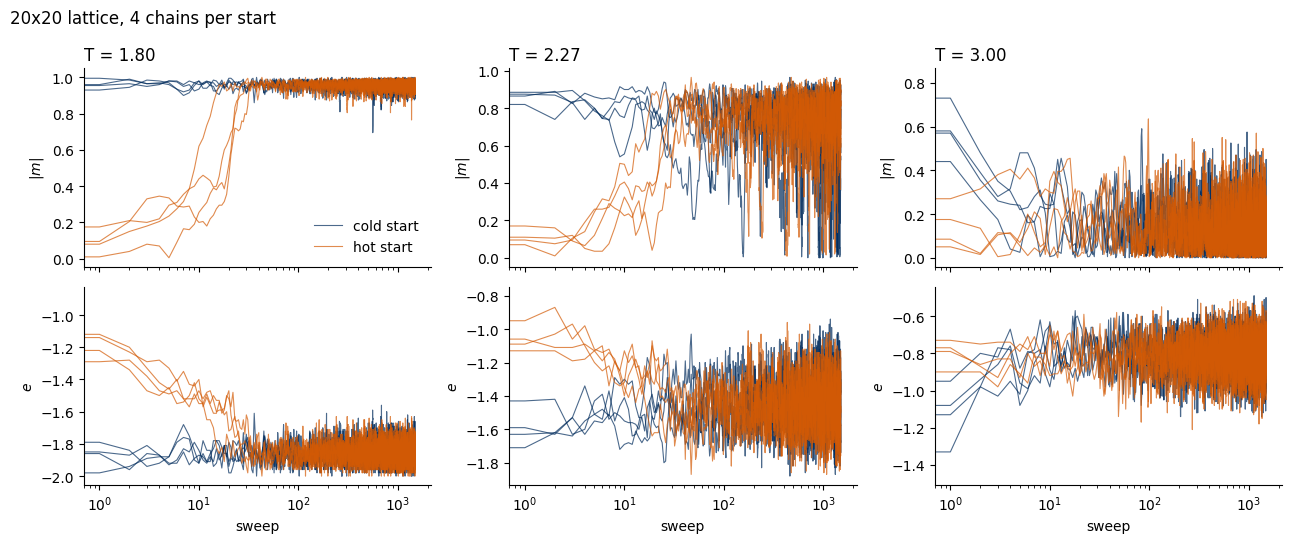

In [4]:
Lx_demo = 20
masks_demo = checkerboard_masks(Lx_demo, Lx_demo)
T_demo = np.array([1.8, 2.27, 3.0], dtype=np.float32)
n_sweeps = 1500
n_chains_demo = 4

starts = {"cold": np.ones((n_chains_demo, len(T_demo), Lx_demo, Lx_demo), np.float32),
          "hot":  rng.choice(np.array([-1, 1], np.float32), size=(n_chains_demo, len(T_demo), Lx_demo, Lx_demo))}
series = {}
for name, s in starts.items():
    beta = (1.0 / T_demo)[None, :, None, None]
    m_t, e_t = [], []
    for t in range(n_sweeps):
        metropolis_sweep(s, beta, masks_demo, rng)
        m_t.append(magnetisation_per_spin(s)); e_t.append(energy_per_spin(s))
    series[name] = (np.array(m_t), np.array(e_t), s.copy())      # arrays of shape (sweep, chain, T)

fig, axes = plt.subplots(2, 3, figsize=(13, 5.5), sharex=True)
for k, T in enumerate(T_demo):
    for name, col in (("cold", UJNavy), ("hot", DSOrange)):
        m_t, e_t, _ = series[name]
        for c in range(n_chains_demo):
            axes[0, k].plot(np.abs(m_t[:, c, k]), color=col, lw=0.8, alpha=0.7, label=f"{name} start" if c == 0 else None)
            axes[1, k].plot(e_t[:, c, k], color=col, lw=0.8, alpha=0.7)
    axes[0, k].set_title(f"T = {T:.2f}", loc="left")
    axes[0, k].set_ylabel(r"$|m|$"); axes[1, k].set_ylabel(r"$e$"); axes[1, k].set_xlabel("sweep")
    axes[0, k].set_xscale("log"); axes[1, k].set_xscale("log")
axes[0, 0].legend(frameon=False)
fig.suptitle(f"{Lx_demo}x{Lx_demo} lattice, {n_chains_demo} chains per start", x=0.01, ha="left")
fig.tight_layout(); plt.show()

The three temperatures behave very differently. At the temperature 3.0, in the disordered phase, the curves from both starts merge after a few sweeps. At 1.8, in the ordered phase, a hot start must *coarsen*: domains of up and down spins grow and merge. Sometimes two domains wrap around the torus as **stripes**, separated by two flat domain walls. A flat wall costs energy but has no curvature that would make it shrink, so it can survive for a very long time, and such a chain sits at $|m|$ well below the ordered value with a slightly higher energy. Whether this happens depends on the random seed; a run with another seed (or more chains) shows this in the snapshots below. Close to $T_c$, at 2.27, the fluctuations are large and slow, an effect called **critical slowing down**.

For the dataset we use a **cold start**: below $T_c$ it is already close to equilibrium, and above $T_c$ it melts quickly.

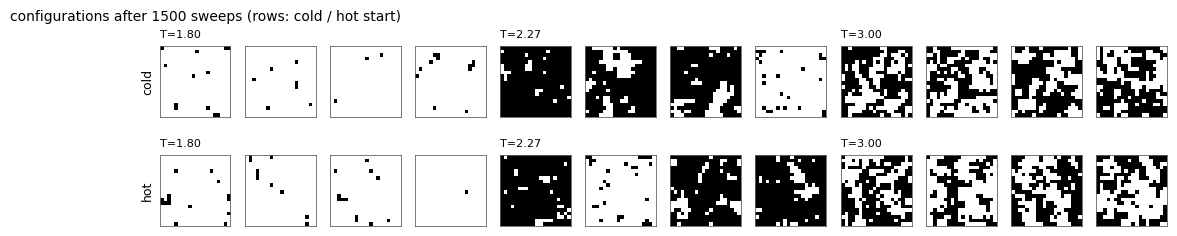

In [5]:
fig, axes = plt.subplots(2, 3 * n_chains_demo, figsize=(13, 2.6))
for r, name in enumerate(("cold", "hot")):
    s_final = series[name][2]
    for k in range(len(T_demo)):
        for c in range(n_chains_demo):
            ax = axes[r, k * n_chains_demo + c]
            show_spins(ax, s_final[c, k])
            if c == 0: ax.set_title(f"T={T_demo[k]:.2f}", fontsize=8, loc="left")
    axes[r, 0].set_ylabel(name, fontsize=9)
fig.suptitle(f"configurations after {n_sweeps} sweeps (rows: cold / hot start)", x=0.01, ha="left", fontsize=10)
plt.show()

<hr/>
## 4. Decorrelation of stored samples

Even after equilibration, consecutive configurations of a Markov chain are **correlated**, because one sweep changes only part of the lattice. For an observable $O$ (here $|m|$) the correlation is measured by the normalised autocorrelation function
$$
C_O(t) = \frac{\langle O_{t_0}O_{t_0+t}\rangle - \langle O\rangle^2}{\langle O^2\rangle-\langle O\rangle^2}, \qquad C_O(0)=1, \tag{15}
$$
and summarised by the **integrated autocorrelation time**
$$
\tau_{\rm int} = \frac12 + \sum_{t\geq1} C_O(t). \tag{16}
$$
Out of $n$ consecutive measurements only about
$$n_{\rm eff}\approx\frac{n}{2\tau_{\rm int}} \tag{17}$$
are effectively independent. We sum $C_O(t)$ up to the first time it drops below zero, because beyond that point the estimate is noise. Two ways of obtaining nearly independent samples follow: store a configuration only after at least about twice $\tau_{\rm int}$ sweeps, or run **many independent chains**. We do both.

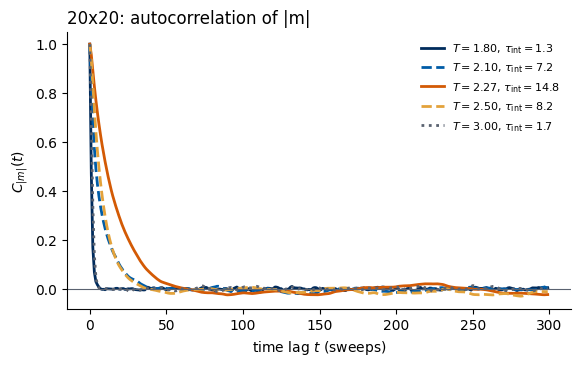

T = 1.80:  tau_int =    1.3 sweeps
T = 2.10:  tau_int =    7.2 sweeps
T = 2.27:  tau_int =   14.8 sweeps
T = 2.50:  tau_int =    8.2 sweeps
T = 3.00:  tau_int =    1.7 sweeps


In [6]:
def autocorrelation(x):
    # x: (time, chains). Normalised autocorrelation averaged over chains, computed with the FFT.
    x = x - x.mean(axis=0)
    n = x.shape[0]
    f = np.fft.rfft(x, n=2 * n, axis=0)
    acf = np.fft.irfft(f * np.conj(f), axis=0)[:n].mean(axis=1)
    return acf / acf[0]

def tau_int(acf):
    cut = np.argmax(acf < 0) if np.any(acf < 0) else len(acf)   # stop at the first negative value
    return 0.5 + acf[1:cut].sum()

T_acf = np.array([1.8, 2.1, 2.27, 2.5, 3.0], dtype=np.float32)
n_chains_acf, n_eq_acf, n_meas_acf = 32, 1000, 3000
s = np.ones((n_chains_acf, len(T_acf), 20, 20), np.float32)
beta = (1.0 / T_acf)[None, :, None, None]
for _ in range(n_eq_acf):
    metropolis_sweep(s, beta, masks_demo, rng)
absm = np.empty((n_meas_acf, n_chains_acf, len(T_acf)), np.float32)
for t in range(n_meas_acf):
    metropolis_sweep(s, beta, masks_demo, rng)
    absm[t] = np.abs(magnetisation_per_spin(s))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
acf_colours = [UJNavy, UJBlue, DSOrange, "#E3A23B", UJGray]
acf_styles = ["-", "--", "-", "--", ":"]
taus = {}
for k, T in enumerate(T_acf):
    acf = autocorrelation(absm[:, :, k])
    taus[T] = tau_int(acf)
    ax.plot(acf[:300], color=acf_colours[k], ls=acf_styles[k], lw=2, label=fr"$T={T:.2f}$, $\tau_{{\rm int}}={taus[T]:.1f}$")
ax.axhline(0, color=UJGray, lw=0.8)
ax.set_xlabel("time lag $t$ (sweeps)"); ax.set_ylabel(r"$C_{|m|}(t)$"); ax.legend(frameon=False, fontsize=8)
ax.set_title("20x20: autocorrelation of |m|", loc="left"); plt.show()
for T, tau in taus.items():
    print(f"T = {T:.2f}:  tau_int = {tau:6.1f} sweeps")

The autocorrelation time is largest close to $T_c$ — **critical slowing down**: near $T_c$ the correlated regions are large, and a local
single-spin update needs many sweeps to change them. (Cluster algorithms such as Wolff's avoid this; we stay with Metropolis because it is simple
and is the algorithm of the Lecture Notes.)

The dataset uses 20 independent chains per temperature and stores a configuration every `n_between` sweeps. Compare `n_between`
with the values of $\tau_{\rm int}$ printed above: far from $T_c$ the stored samples of one chain are practically independent; close to $T_c$ they are
not fully independent, but the 20 chains are.

<hr/>
## 5. Generating the dataset

We sample a grid of temperatures from 1.0 to 3.5 in steps of 0.05. All temperatures and all chains are updated together as one array of shape `(chains, temperatures, Ny, Nx)`.

One more detail concerns symmetry. The Ising energy is symmetric under a **global spin flip**, which reverses every spin, but a cold start puts every low-temperature chain into the state of positive magnetisation, and on our time scales it stays there. We restore the symmetry exactly by flipping each stored configuration with probability one half. Without this step a network could learn the trivial rule "black means ordered".

One sample of the data set is an $N_y\times N_x$ array of spins $\pm1$, stored as 8-bit integers, together with the temperature at which it was drawn; Lab 011 derives its labels (ordered or disordered) from that temperature. For the $20\times20$ lattice the file holds 51 temperatures with 200 configurations each, 10 200 samples in all. The lattice size is set by `Nx` and `Ny`; both must be even.

In [7]:
Nx, Ny = 20, 20                                        # lattice size (even numbers)
temperatures = np.round(np.arange(1.0, 3.5 + 1e-9, 0.05), 2)
n_chains   = 20                                        # independent chains per temperature
n_samples  = 10                                        # stored configurations per chain  -> 200 per temperature
n_equil    = 1000                                      # burn-in sweeps
n_between  = 20                                        # sweeps between stored configurations

def generate_dataset(Nx, Ny, temperatures, n_chains, n_samples, n_equil, n_between, rng):
    masks = checkerboard_masks(Ny, Nx)
    beta = (1.0 / temperatures.astype(np.float32))[None, :, None, None]
    s = np.ones((n_chains, len(temperatures), Ny, Nx), np.float32)       # cold start
    for _ in range(n_equil):
        metropolis_sweep(s, beta, masks, rng)
    stored = np.empty((n_samples, n_chains, len(temperatures), Ny, Nx), np.int8)
    for k in range(n_samples):
        for _ in range(n_between):
            metropolis_sweep(s, beta, masks, rng)
        stored[k] = s
    configs = stored.transpose(2, 0, 1, 3, 4).reshape(len(temperatures), n_samples * n_chains, Ny, Nx)
    flip = rng.choice(np.array([-1, 1], np.int8), size=configs.shape[:2])  # random global spin flip
    return configs * flip[:, :, None, None]

t0 = time.time()
configs = generate_dataset(Nx, Ny, temperatures, n_chains, n_samples, n_equil, n_between, rng)
print(f"configs: shape {configs.shape} (temperatures, samples, Ny, Nx), dtype {configs.dtype}, "
      f"generated in {time.time() - t0:.1f} s")

os.makedirs("data", exist_ok=True)
path = f"data/ising_Nx{Nx}_Ny{Ny}.npz"
np.savez_compressed(path, configs=configs, T=temperatures, Nx=Nx, Ny=Ny,
                    n_equil=n_equil, n_between=n_between, n_chains=n_chains)
print(f"saved to {path}  ({os.path.getsize(path) / 1e6:.2f} MB)")

configs: shape (51, 200, 20, 20) (temperatures, samples, Ny, Nx), dtype int8, generated in 20.5 s


saved to data/ising_Nx20_Ny20.npz  (0.36 MB)


<hr/>
## 6. Sample configurations

Each column of the figure shows three stored configurations at one temperature, from deep in the ordered phase (temperature 1.2) to the disordered phase (3.2), with the columns between 1.9 and 2.6 bracketing $T_c$.

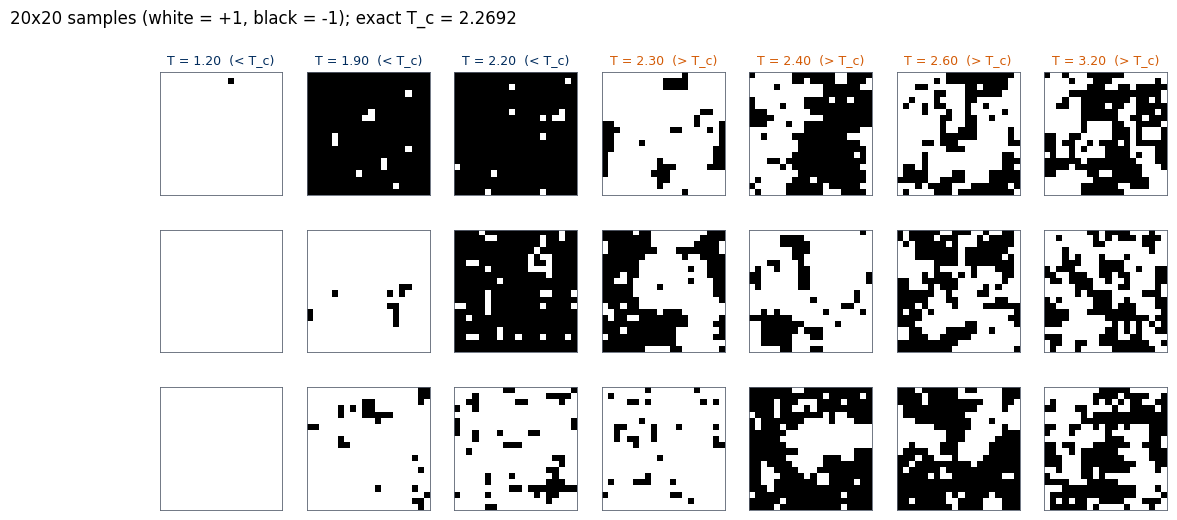

In [8]:
show_T = [1.2, 1.9, 2.2, 2.3, 2.4, 2.6, 3.2]
fig, axes = plt.subplots(3, len(show_T), figsize=(13, 5.8))
for k, T in enumerate(show_T):
    i = np.argmin(np.abs(temperatures - T))
    for r in range(3):
        ax = axes[r, k]
        show_spins(ax, configs[i, r * 37])
    axes[0, k].set_title(f"T = {temperatures[i]:.2f}" + ("  (< T_c)" if temperatures[i] < TC else "  (> T_c)"),
                         fontsize=9, color=UJNavy if temperatures[i] < TC else DSOrange)
fig.suptitle(f"{Nx}x{Ny} samples (white = +1, black = -1); exact T_c = {TC:.4f}", x=0.01, ha="left")
plt.show()

Close to $T_c$ (columns 2.2–2.4) configurations from the two phases are hard to tell apart by eye: we see clusters of all sizes. This is the region the CNN of Lab 011 will *not* see during training.
<hr/>
## 7. Thermodynamics and Onsager's exact solution

The samples can now be compared with the exact results for the infinite lattice, with $J$ set to 1. With the reduced coupling
$$K=\beta J \tag{18}$$
and
$$\kappa = \frac{2\sinh 2K}{\cosh^2 2K}, \tag{19}$$
the free energy found by Onsager (1944) reads
$$
-\beta f = \frac{\ln Z}{N} = \ln\left(2\cosh 2K\right) + \frac{1}{2\pi}\int_0^\pi d\phi\, \ln\frac{1+\sqrt{1-\kappa^2\sin^2\phi}}{2}. \tag{20}
$$
The energy per spin is its derivative,
$$u = -\frac{\partial}{\partial\beta}\frac{\ln Z}{N}, \tag{21}$$
which evaluates to
$$
u = -\coth 2K\left[1+\frac{2}{\pi}\left(2\tanh^2 2K-1\right)K_1(\kappa)\right], \tag{22}
$$
$$
K_1(\kappa)=\int_0^{\pi/2}\frac{d\phi}{\sqrt{1-\kappa^2\sin^2\phi}}. \tag{23}
$$
The spontaneous magnetisation was announced by Onsager in 1949 and proved by Yang in 1952:
$$
M = \begin{cases}\left[1-\sinh^{-4}2K\right]^{1/8}, & T<T_c,\\[2pt] 0, & T>T_c.\end{cases} \tag{24}
$$

Equation (22) is checked against a numerical derivative of the free-energy integral, equation (20). SciPy's `ellipk(m)` takes as its parameter the square of $\kappa$.

In [9]:
def lnZ_per_spin(T):
    K = 1.0 / T
    kap = 2 * np.sinh(2 * K) / np.cosh(2 * K) ** 2
    integrand = lambda p: np.log(0.5 * (1 + np.sqrt(max(0.0, 1 - kap**2 * np.sin(p) ** 2))))
    I, _ = quad(integrand, 0, np.pi, points=[np.pi / 2], limit=200)
    return np.log(2 * np.cosh(2 * K)) + I / (2 * np.pi)

def u_exact(T):
    K = 1.0 / np.asarray(T, float)
    kap = 2 * np.sinh(2 * K) / np.cosh(2 * K) ** 2
    return -1 / np.tanh(2 * K) * (1 + 2 / np.pi * (2 * np.tanh(2 * K) ** 2 - 1) * ellipk(kap**2))

def M_exact(T):
    T = np.asarray(T, float)
    out = np.zeros_like(T)
    low = T < TC
    out[low] = (1 - np.sinh(2 / T[low]) ** -4) ** 0.125
    return out

for T in (1.5, 2.0, 2.6, 3.5):                        # u from the formula vs -d lnZ / d beta (central difference)
    b, h = 1 / T, 1e-5
    u_num = -(lnZ_per_spin(1 / (b + h)) - lnZ_per_spin(1 / (b - h))) / (2 * h)
    print(f"T = {T}:  formula u = {u_exact(T):+.8f}   -d lnZ/d beta = {u_num:+.8f}")
print(f"u(T_c) from the formula: {u_exact(TC * (1 + 1e-9)):.6f};  -sqrt(2) = {-np.sqrt(2):.6f}")

T = 1.5:  formula u = -1.95111657   -d lnZ/d beta = -1.95111657
T = 2.0:  formula u = -1.74556458   -d lnZ/d beta = -1.74556457
T = 2.6:  formula u = -1.02829364   -d lnZ/d beta = -1.02829364
T = 3.5:  formula u = -0.66012173   -d lnZ/d beta = -0.66012173
u(T_c) from the formula: -1.414214;  -sqrt(2) = -1.414214


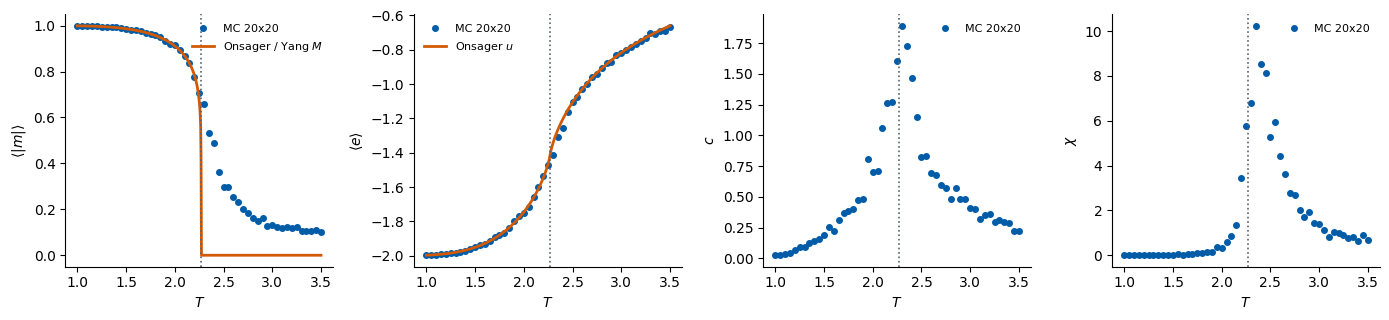

peak of c   at T = 2.30
peak of chi at T = 2.35      exact T_c = 2.2692


In [10]:
cf = configs.astype(np.float32)
N = Nx * Ny
e_s = energy_per_spin(cf)                             # shape (temperatures, samples)
m_s = magnetisation_per_spin(cf)
E_mean, absM_mean = e_s.mean(1), np.abs(m_s).mean(1)
C_heat = N * e_s.var(1) / temperatures**2
chi = N * ((m_s**2).mean(1) - np.abs(m_s).mean(1) ** 2) / temperatures

Tf = np.linspace(1.0, 3.5, 600)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.3))
panels = [(absM_mean, r"$\langle|m|\rangle$", M_exact(Tf), "Onsager / Yang $M$"),
          (E_mean, r"$\langle e\rangle$", u_exact(Tf), "Onsager $u$"),
          (C_heat, r"$c$", None, None),
          (chi, r"$\chi$", None, None)]
for ax, (y, lab, yex, exlab) in zip(axes, panels):
    ax.plot(temperatures, y, "o", ms=4, color=UJBlue, label=f"MC {Nx}x{Ny}")
    if yex is not None:
        ax.plot(Tf, yex, color=DSOrange, lw=2, label=exlab)
    ax.axvline(TC, color=UJGray, ls=":", lw=1.2)
    ax.set_xlabel("$T$"); ax.set_ylabel(lab)
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

i_c, i_chi = np.argmax(C_heat), np.argmax(chi)
print(f"peak of c   at T = {temperatures[i_c]:.2f}")
print(f"peak of chi at T = {temperatures[i_chi]:.2f}      exact T_c = {TC:.4f}")

Far from $T_c$ the Monte Carlo points lie on the exact curves: a $20\times20$ lattice is already "large" there, because the correlation length is short. Near $T_c$ the finite lattice deviates. $\langle|m|\rangle$ does not drop to zero at $T_c$ but has a smooth tail above it, whereas the exact $M$ of equation (24) has an infinite slope at $T_c$, which no finite system can have. Likewise $c$ and $\chi$ have **finite peaks** instead of divergences; the peaks (at the temperatures 2.30 and 2.35 in the printed output) lie close to the exact critical temperature
$$T_c=\frac{2}{\ln\big(1+\sqrt2\big)}\approx2.2692, \tag{25}$$
but not exactly at it.
<hr/>
## 8. Finite-size effects

A phase transition is a **non-analyticity** of $\ln Z$ (Lecture 4). For finite $N$, $Z$ is a finite sum of exponentials of $\beta$, an analytic function, so **a finite lattice has no sharp transition**. What we see are *pseudo-critical* features (peaks of $c$ and $\chi$, the steepest drop of $\langle|m|\rangle$) whose positions $T^*(L)$ approach $T_c$ as $L$ grows without bound, while the peaks grow.

The mechanism is the divergence of the correlation length $\xi(T)$ at $T_c$. On a lattice of size $L$ the critical behaviour is cut off when
$$\xi(T)\approx L, \tag{26}$$
so the transition is rounded over a window that shrinks as $L$ grows. Since
$$\xi\sim|T-T_c|^{-\nu}, \tag{27}$$
the window is
$$|T-T_c|\sim L^{-1/\nu}. \tag{28}$$

The prediction is tested by computing $\chi(T)$ for the lattice sizes 10, 20 and 40 on a fine grid around $T_c$, measuring after every sweep.

finite-size scan done in 71 s


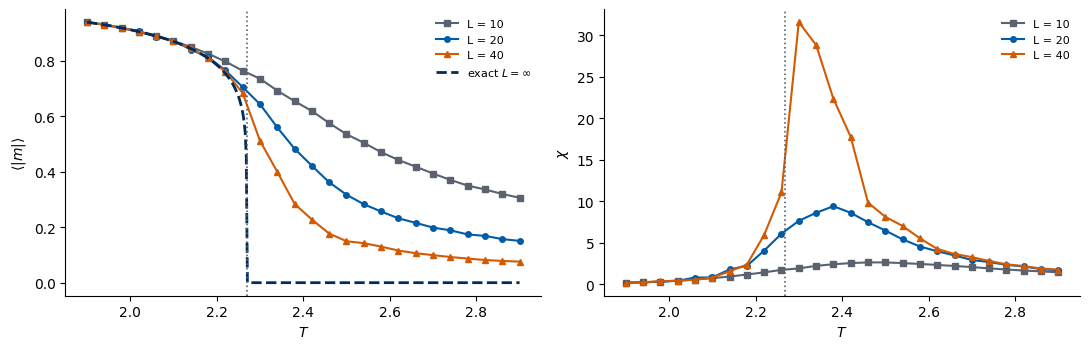

 L   T*(L) = argmax chi   chi_max    T*(L) - T_c
 10   2.46                  2.64    +0.191
 20   2.38                  9.42    +0.111
 40   2.30                 31.62    +0.031


In [11]:
def chi_scan(L, temps, n_chains, n_eq, n_meas, rng):
    # Measure <|m|> and chi on a temperature grid; measurements after every sweep (correlated, but averages are fine).
    masks = checkerboard_masks(L, L)
    beta = (1.0 / temps.astype(np.float32))[None, :, None, None]
    s = np.ones((n_chains, len(temps), L, L), np.float32)
    for _ in range(n_eq):
        metropolis_sweep(s, beta, masks, rng)
    m1, m2 = np.zeros(len(temps)), np.zeros(len(temps))
    for _ in range(n_meas):
        metropolis_sweep(s, beta, masks, rng)
        m = np.abs(magnetisation_per_spin(s))            # (chains, temps)
        m1 += m.mean(0); m2 += (m**2).mean(0)
    m1, m2 = m1 / n_meas, m2 / n_meas
    return m1, L * L * (m2 - m1**2) / temps

T_fs = np.round(np.arange(1.9, 2.9 + 1e-9, 0.04), 2)
fs = {}
t0 = time.time()
for L, nch in ((10, 32), (20, 16), (40, 8)):
    fs[L] = chi_scan(L, T_fs, n_chains=nch, n_eq=1000, n_meas=2000, rng=rng)
print(f"finite-size scan done in {time.time() - t0:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for (L, (m1, ch)), col, mk in zip(fs.items(), (UJGray, UJBlue, DSOrange), ("s", "o", "^")):
    axes[0].plot(T_fs, m1, "-" + mk, color=col, ms=4, label=f"L = {L}")
    axes[1].plot(T_fs, ch, "-" + mk, color=col, ms=4, label=f"L = {L}")
Tf2 = np.linspace(1.9, 2.9, 400)
axes[0].plot(Tf2, M_exact(Tf2), color=UJNavy, lw=2, ls="--", label=r"exact $L=\infty$")
for ax, lab in zip(axes, (r"$\langle|m|\rangle$", r"$\chi$")):
    ax.axvline(TC, color=UJGray, ls=":", lw=1.2); ax.set_xlabel("$T$"); ax.set_ylabel(lab); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

print(" L   T*(L) = argmax chi   chi_max    T*(L) - T_c")
for L, (m1, ch) in fs.items():
    i = np.argmax(ch)
    print(f"{L:3d}   {T_fs[i]:.2f}               {ch[i]:7.2f}    {T_fs[i] - TC:+.3f}")

As $L$ grows, the drop of $\langle|m|\rangle$ becomes steeper and approaches the exact curve, and the peak of $\chi$ grows and moves toward $T_c$: in the table above $T^*(L)$ goes from 2.46 to 2.38 to 2.30 for the lattice sizes 10, 20 and 40, while $\chi_{\max}$ rises from 2.64 to 31.62 (the grid spacing 0.04 limits the resolution of $T^*(L)$).

Locating $T_c$ from finite data is therefore a **finite-size extrapolation**, not a single measurement. The CNN in Lab 011 faces exactly the same limitation: its estimate $\bar T_c$ is a pseudo-critical temperature of an $L\times L$ lattice. What the samples **do not** tell us is *why* there is a transition, or why it sits at the value of equation (25). That answer came from Onsager's exact solution (Lecture 4 and Lab 012).
<hr/>
## 9. Exercises
1. Change `Nx, Ny` in Section 5 to a rectangular lattice, e.g. $40\times10$. How do the snapshots and $\langle|m|\rangle(T)$ change? (Hint: the shorter side limits $\xi$.)
2. Start the dataset from a **hot** start at all temperatures and repeat Section 7. Which temperatures are affected, and why?
3. Measure $\tau_{\rm int}$ close to $T_c$ for the lattice sizes 10, 20 and 40. How does it grow with $L$?
4. Implement the heat-bath (Glauber) rule
$$p(s_i=+1)=\frac{1}{1+e^{-2\beta\phi_i}} \tag{29}$$
instead of Metropolis, and check that the averages do not change.